# 04. Modelo preditivo (H3) e score de risco

**Etapa CRISP-DM:** modelagem preditiva e avaliação.

**H3:** a logística completa (RFM + campanhas + cupons + diversidade + tendência) tem AUC maior, no teste, do que a logística só com RFM e do que a regra de recência.
**Refutação:** IC 95% da diferença de AUC (bootstrap) inclui zero.

**Validação temporal:** treino = corte 53 a 78 (rótulo nas semanas 79 a 86); teste = corte 69 a 94 (rótulo nas semanas 95 a 102). O teste é um período posterior, como seria no uso real.

**Score:** o modelo completo é reajustado no corte mais recente com rótulo (teste) e aplicado às semanas 77 a 102, gerando a lista priorizada.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = RAIZ / "reports" / "modelo"; REP.mkdir(parents=True, exist_ok=True)
FIG = RAIZ / "reports" / "figuras"
PROC = RAIZ / "data" / "processed"
base = pd.read_csv(PROC / "base_modelagem.csv")
base["log_freq"] = np.log1p(base["frequencia"])
base["log_monetario"] = np.log1p(base["monetario"])
base["recencia_sem"] = base["recencia_dias"] / 7
Y = "inativo_8s"
tr = base[base.corte == "treino"].reset_index(drop=True)
te = base[base.corte == "teste"].reset_index(drop=True)
sc = base[base.corte == "score"].reset_index(drop=True)
NUM = {"n_treino": len(tr), "inativos_treino": int(tr[Y].sum()), "n_teste": len(te), "inativos_teste": int(te[Y].sum())}
NUM

{'n_treino': 2409,
 'inativos_treino': 213,
 'n_teste': 2417,
 'inativos_teste': 244}

## 1. Modelos comparados

In [2]:
RFM = ["recencia_sem", "log_freq", "log_monetario"]
COMPLETO = RFM + ["n_campanhas", "n_resgates", "n_departamentos", "tendencia_gasto"]

def treinar_logistica(X, y, ponderar=True):
    # 1) padroniza as variáveis (média 0, desvio 1) para ficarem na mesma escala
    padronizador = StandardScaler().fit(X)
    # 2) ajusta a regressão logística; class_weight="balanced" dá mais peso aos inativos, que são cerca de 10%
    modelo = LogisticRegression(class_weight="balanced" if ponderar else None, max_iter=1000)
    modelo.fit(padronizador.transform(X), y)
    return padronizador, modelo

def prever(padronizador, modelo, X):
    # probabilidade de ser inativo (coluna 1 = classe "inativo")
    return modelo.predict_proba(padronizador.transform(X))[:, 1]

modelos = {"regra_recencia": None, "logistica_rfm": RFM, "logistica_completa": COMPLETO}
score_tr, score_te, ajustados = {}, {}, {}
for nome, cols in modelos.items():
    if cols is None:  # regra simples: quanto mais dias sem comprar, maior o risco
        score_tr[nome], score_te[nome] = tr["recencia_dias"].values, te["recencia_dias"].values
        continue
    pad, mod = treinar_logistica(tr[cols], tr[Y].astype(int))
    ajustados[nome] = (pad, mod)
    score_tr[nome], score_te[nome] = prever(pad, mod, tr[cols]), prever(pad, mod, te[cols])

## 2. Métricas no teste
O limiar de classificação de cada modelo é escolhido **no treino** (maior F1) e aplicado sem mudança no teste. Também mede-se a precisão nos 10% de maior risco, que é como a área comercial usaria a lista.

In [3]:
# limiar: a partir de qual nota o cliente é classificado como "vai inativar"
def limiar_f1(y, s):
    cand = np.unique(np.quantile(s, np.linspace(0.5, 0.99, 50)))
    return max(cand, key=lambda t: f1_score(y, s >= t))

ytr, yte = tr[Y].astype(int).values, te[Y].astype(int).values
taxa_base = yte.mean()
linhas, previsoes = [], {}
for nome in modelos:
    t = limiar_f1(ytr, score_tr[nome]); pred = score_te[nome] >= t
    previsoes[nome] = pred
    top = score_te[nome] >= np.quantile(score_te[nome], 0.9)
    linhas.append({"modelo": nome, "AUC_treino": roc_auc_score(ytr, score_tr[nome]), "AUC_teste": roc_auc_score(yte, score_te[nome]),
                   "acuracia": accuracy_score(yte, pred),
                   "precisao": precision_score(yte, pred), "recall": recall_score(yte, pred), "F1": f1_score(yte, pred),
                   "precisao_top10": yte[top].mean(), "lift_top10": yte[top].mean() / taxa_base})
met = pd.DataFrame(linhas).round(3)
met.to_csv(REP / "metricas_teste.csv", index=False)
NUM["metricas_teste"] = met.to_dict("records"); NUM["taxa_base_teste"] = round(float(taxa_base), 4)
met

,modelo,AUC_treino,AUC_teste,acuracia,precisao,recall,F1,precisao_top10,lift_top10
0,regra_recencia,0.853,0.815,0.873,0.395,0.488,0.437,0.424,4.205
1,logistica_rfm,0.892,0.862,0.876,0.405,0.492,0.444,0.421,4.175
2,logistica_completa,0.894,0.857,0.878,0.409,0.471,0.438,0.430,4.257


### Matriz de confusão do modelo completo (teste)
Linhas = realidade, colunas = previsão. Mostra acertos e erros de cada tipo.

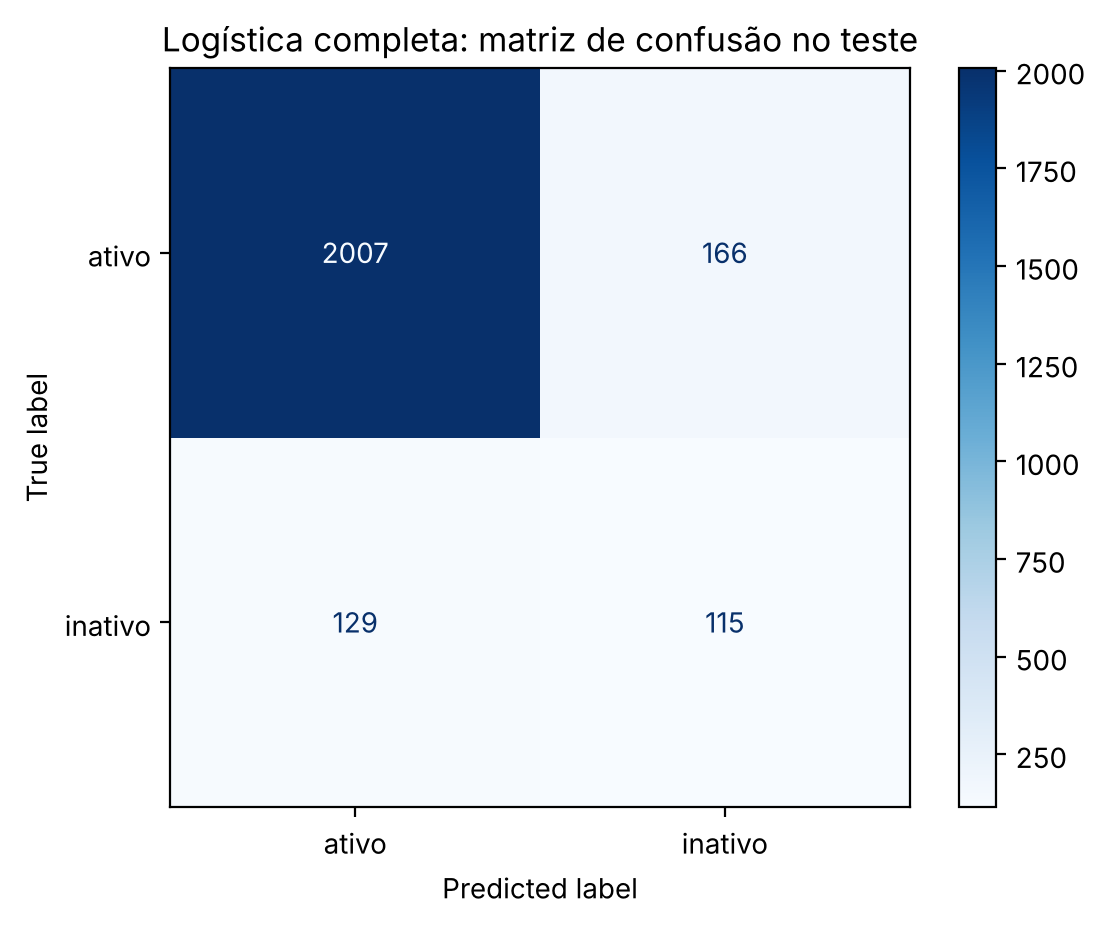

{'vn': 2007, 'fp': 166, 'fn': 129, 'vp': 115}

In [4]:
mc = confusion_matrix(yte, previsoes["logistica_completa"])
NUM["matriz_confusao_completa"] = {"vn": int(mc[0, 0]), "fp": int(mc[0, 1]), "fn": int(mc[1, 0]), "vp": int(mc[1, 1])}
ConfusionMatrixDisplay(mc, display_labels=["ativo", "inativo"]).plot(cmap="Blues")
plt.title("Logística completa: matriz de confusão no teste")
plt.savefig(FIG / "04_matriz_confusao.png", dpi=150, bbox_inches="tight"); plt.show()
NUM["matriz_confusao_completa"]

## 3. Teste de H3: bootstrap da diferença de AUC (1.000 reamostragens do teste)

In [5]:
rng = np.random.default_rng(42)
B = 1000
dif = {"completa_menos_rfm": [], "completa_menos_recencia": [], "rfm_menos_recencia": []}
n = len(yte)
for _ in range(B):
    i = rng.integers(0, n, n)
    if yte[i].sum() in (0, len(i)):
        continue
    a = {k: roc_auc_score(yte[i], score_te[k][i]) for k in modelos}
    dif["completa_menos_rfm"].append(a["logistica_completa"] - a["logistica_rfm"])
    dif["completa_menos_recencia"].append(a["logistica_completa"] - a["regra_recencia"])
    dif["rfm_menos_recencia"].append(a["logistica_rfm"] - a["regra_recencia"])
boot = pd.DataFrame([{"comparacao": k, "dif_media": np.mean(v), "IC95_inf": np.percentile(v, 2.5),
                      "IC95_sup": np.percentile(v, 97.5), "reamostragens": len(v)} for k, v in dif.items()]).round(4)
boot.to_csv(REP / "bootstrap_auc.csv", index=False)
NUM["bootstrap_auc"] = boot.to_dict("records")
boot

,comparacao,dif_media,IC95_inf,IC95_sup,reamostragens
0,completa_menos_rfm,-0.0048,-0.0114,0.0019,1000
1,completa_menos_recencia,0.0415,0.0173,0.0661,1000
2,rfm_menos_recencia,0.0462,0.0241,0.0706,1000


In [6]:
ok = boot.set_index("comparacao")
h3_rfm = ok.loc["completa_menos_rfm", "IC95_inf"] > 0
h3_rec = ok.loc["completa_menos_recencia", "IC95_inf"] > 0
if h3_rfm and h3_rec:
    v = "aceita: a completa supera as duas referências (IC 95% acima de zero)"
elif h3_rec:
    v = "aceita parcialmente: supera a regra de recência, mas não a logística só com RFM (IC inclui zero)"
else:
    v = "refutada: o IC 95% da diferença inclui zero nas duas comparações"
NUM["H3_veredito"] = v
print("H3:", v)

H3: aceita parcialmente: supera a regra de recência, mas não a logística só com RFM (IC inclui zero)


## 4. Curvas ROC e coeficientes do modelo completo

,coef_padronizado,OR_por_desvio
n_resgates,-0.730,0.482
log_freq,-0.679,0.507
n_departamentos,-0.408,0.665
n_campanhas,-0.377,0.686
log_monetario,-0.094,0.910
tendencia_gasto,-0.085,0.919
recencia_sem,0.640,1.896


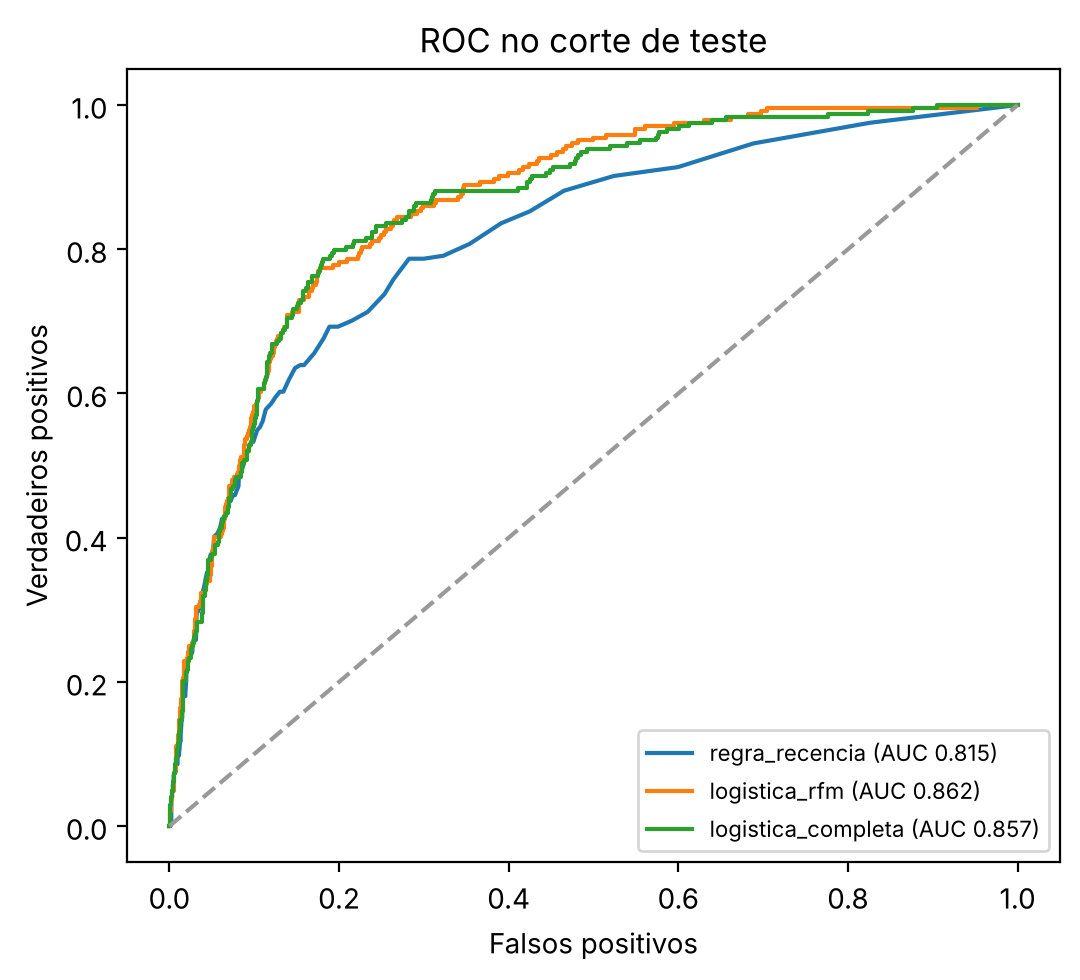

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for nome in modelos:
    fpr, tpr, _ = roc_curve(yte, score_te[nome])
    ax.plot(fpr, tpr, label=f"{nome} (AUC {roc_auc_score(yte, score_te[nome]):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#999"); ax.set_xlabel("Falsos positivos"); ax.set_ylabel("Verdadeiros positivos")
ax.set_title("ROC no corte de teste"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "04_roc_teste.png", dpi=150)

coef = pd.Series(ajustados["logistica_completa"][1].coef_[0], index=COMPLETO).sort_values()
coef_df = coef.rename("coef_padronizado").to_frame().assign(OR_por_desvio=np.exp(coef)).round(3)
coef_df.to_csv(REP / "coeficientes_completa.csv")
NUM["coeficientes_completa"] = coef_df["coef_padronizado"].to_dict()
coef_df

## 5. Score de risco atual (semanas 77 a 102)
O modelo completo é reajustado no corte de teste e aplicado ao corte `score`. As faixas usam a posição no ranking:
**alto** = 10% de maior risco (a taxa de inativação histórica fica perto de 10%), **médio** = próximos 20%, **baixo** = restante.
**Prioridade** = probabilidade × gasto das últimas 26 semanas: a receita esperada em risco de cada domicílio.
Para o score final, a logística é ajustada **sem** ponderação de classes, para que a saída seja uma probabilidade e a soma da prioridade tenha leitura em dinheiro.

In [8]:
# sem ponderação de classes: assim o score é uma probabilidade utilizável (a ponderação infla os valores)
pad_final, mod_final = treinar_logistica(te[COMPLETO], te[Y].astype(int), ponderar=False)
sc["score_risco"] = prever(pad_final, mod_final, sc[COMPLETO])
q90, q70 = sc["score_risco"].quantile([0.9, 0.7])
sc["faixa_risco"] = np.where(sc.score_risco >= q90, "alto", np.where(sc.score_risco >= q70, "medio", "baixo"))
sc["prioridade"] = sc["score_risco"] * sc["monetario"]
sc["rank_prioridade"] = sc["prioridade"].rank(ascending=False, method="first").astype(int)
cols = ["household_key", "score_risco", "faixa_risco", "prioridade", "rank_prioridade", "recencia_dias", "frequencia",
        "monetario", "ticket_medio", "n_departamentos", "n_campanhas", "n_resgates", "renda", "tamanho_domicilio"]
lista = sc[cols].sort_values("rank_prioridade")
lista.to_csv(PROC / "score_risco.csv", index=False)
fx = lista.groupby("faixa_risco").agg(domicilios=("household_key", "size"), receita_26s=("monetario", "sum"),
                                      recencia_media=("recencia_dias", "mean")).round(2)
NUM["faixas_score"] = fx.to_dict("index")
NUM["receita_em_risco_alto"] = round(float(fx.loc["alto", "receita_26s"]), 2)
NUM["receita_esperada_em_risco_total"] = round(float(sc["prioridade"].sum()), 2)
NUM["receita_esperada_em_risco_top100"] = round(float(lista.head(100)["prioridade"].sum()), 2)
NUM["prob_media_score"] = round(float(sc["score_risco"].mean()), 4)
fx

,domicilios,receita_26s,recencia_media
faixa_risco,,,
alto,244,18297.19,80.83
baixo,1702,2196616.57,6.99
medio,486,113938.66,25.27


## 6. Achados

In [9]:
json.dump(NUM, open(REP / "numeros_modelo.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)
m = met.set_index("modelo")
for k in modelos:
    print(f"{k}: AUC teste {m.loc[k, 'AUC_teste']}, precisão nos 10% de maior risco {m.loc[k, 'precisao_top10']} (lift {m.loc[k, 'lift_top10']}x)")
for r in NUM["bootstrap_auc"]:
    print(f"{r['comparacao']}: {r['dif_media']} (IC 95% {r['IC95_inf']} a {r['IC95_sup']})")
print("H3:", NUM["H3_veredito"])
print(f"Receita esperada em risco (soma de probabilidade x gasto): {NUM['receita_esperada_em_risco_total']}; nos 100 primeiros da lista: {NUM['receita_esperada_em_risco_top100']}")
print(f"Faixa alta: {NUM['faixas_score']['alto']['domicilios']} domicílios, receita de 26 semanas em risco {NUM['receita_em_risco_alto']}")

regra_recencia: AUC teste 0.815, precisão nos 10% de maior risco 0.424 (lift 4.205x)
logistica_rfm: AUC teste 0.862, precisão nos 10% de maior risco 0.421 (lift 4.175x)
logistica_completa: AUC teste 0.857, precisão nos 10% de maior risco 0.43 (lift 4.257x)
completa_menos_rfm: -0.0048 (IC 95% -0.0114 a 0.0019)
completa_menos_recencia: 0.0415 (IC 95% 0.0173 a 0.0661)
rfm_menos_recencia: 0.0462 (IC 95% 0.0241 a 0.0706)
H3: aceita parcialmente: supera a regra de recência, mas não a logística só com RFM (IC inclui zero)
Receita esperada em risco (soma de probabilidade x gasto): 75298.65; nos 100 primeiros da lista: 9228.16
Faixa alta: 244 domicílios, receita de 26 semanas em risco 18297.19
